# Midterm - Hyperparameter Optimization: Predicting Forest Cover Type

Author: Vadim Egorov

**Objective:** build a baseline classifier, tune its hyperparameters with cross-validation, and check whether the tuning actually improves performance on unseen data.

**Dataset:** [Covertype](https://archive.ics.uci.edu/dataset/31/covertype) (UCI Machine Learning Repository).

### The problem
Forest managers need to know which trees grow where, for fire planning, wildlife habitat and conservation. Surveying every patch of forest on foot is slow and expensive, especially in remote wilderness. If the tree type can be predicted from **map data alone** large areas can be mapped without sending field crews.

The Covertype dataset has **581,012 cells**. Each cell is a 30 m × 30 m patch of forest in four wilderness areas of the Roosevelt National Forest in northern Colorado. The labels come from US Forest Service records, and the features come from US Geological Survey and Forest Service map data.

**Target:** `Cover_Type`, the main tree type in the cell (7 classes):
**Features (54):**
- 10 numeric:
  - Terrain: `Elevation` (m), `Aspect` (compass direction the slope faces, in degrees), `Slope` (degrees).
  - Distances in meters: horizontal and vertical distance to the nearest water (`Hydrology`), and horizontal distance to the nearest road (`Roadways`) and to the nearest wildfire ignition point (`Fire_Points`).
  - `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm`: how much sunlight reaches the cell at that time of day (0 = full shadow, 255 = full sun).
- 4 binary `Wilderness_Area` columns: Rawah, Neota, Comanche Peak, Cache la Poudre.
- 40 binary `Soil_Type` columns.

**Questions:**
1. How well does a baseline classifier predict the cover type?
2. Which hyperparameters matter, and does tuning them with 5-fold cross-validation improve performance on the test set?
3. Is there evidence of overfitting or underfitting, and which model would I recommend?

## 1. Imports + Setup

In [1]:
# ucimlrepo isn't preinstalled in Google Colab
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier

# Larger default size for all plots
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 12

## 2. Load Data

In [ ]:
# Fetch dataset (the dataset is big so it may take a while to download)
covertype = fetch_ucirepo(id=31)

# Data as pandas dataframes
X = covertype.data.features # type: ignore
y = covertype.data.targets['Cover_Type'] # type: ignore

df = X.copy()
df['Cover_Type'] = y

df

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581007,2396,153,20,85,17,108,240,237,118,837,...,0,0,0,0,0,0,0,1,0,3
581008,2391,152,19,67,12,95,240,237,119,845,...,0,0,0,0,0,0,0,1,0,3
581009,2386,159,17,60,7,90,236,241,130,854,...,0,0,0,0,0,0,0,1,0,3
581010,2384,170,15,60,5,90,230,245,143,864,...,0,0,0,0,0,0,0,1,0,3


In [4]:
# Some constants
# Readable names (from the UCI description)
COVER_NAMES = {
    1: 'Spruce/Fir',
    2: 'Lodgepole Pine',
    3: 'Ponderosa Pine',
    4: 'Cottonwood/Willow',
    5: 'Aspen',
    6: 'Douglas-fir',
    7: 'Krummholz'
}

WILDERNESS_NAMES = {
    'Wilderness_Area1': 'Rawah',
    'Wilderness_Area2': 'Neota',
    'Wilderness_Area3': 'Comanche Peak',
    'Wilderness_Area4': 'Cache la Poudre'
}

## 3. EDA - Exploratory Data Analysis

In [5]:
display(df.shape)
display(df.dtypes)
display(df.dtypes.value_counts())

(581012, 55)

Elevation                             int64
Aspect                                int64
Slope                                 int64
Horizontal_Distance_To_Hydrology      int64
Vertical_Distance_To_Hydrology        int64
Horizontal_Distance_To_Roadways       int64
Hillshade_9am                         int64
Hillshade_Noon                        int64
Hillshade_3pm                         int64
Horizontal_Distance_To_Fire_Points    int64
Wilderness_Area1                      int64
Soil_Type1                            int64
Soil_Type2                            int64
Soil_Type3                            int64
Soil_Type4                            int64
Soil_Type5                            int64
Soil_Type6                            int64
Soil_Type7                            int64
Soil_Type8                            int64
Soil_Type9                            int64
Soil_Type10                           int64
Soil_Type11                           int64
Soil_Type12                     

int64    55
Name: count, dtype: int64

All 54 features and the target are stored as integers.

### 3.1 Missing values and duplicates

In [6]:
missing_values_num = df.isnull().sum().sum()
duplicate_rows_num = df.duplicated().sum()

print(f"Number of missing values: {missing_values_num}")
print(f"Number of duplicate rows: {duplicate_rows_num}")

Number of missing values: 0
Number of duplicate rows: 0


No missing values and no duplicate rows.

### 3.2 Target: cover type

In [7]:
class_counts = y.value_counts().sort_index()

target_summary = pd.DataFrame({
    'Cover type': class_counts.index.map(COVER_NAMES),
    'Count': class_counts.values,
    'Share (%)': (class_counts.values / len(y) * 100).round(2),
}, index=class_counts.index)

target_summary

,Cover type,Count,Share (%)
Cover_Type,,,
1,Spruce/Fir,211840,36.46
2,Lodgepole Pine,283301,48.76
3,Ponderosa Pine,35754,6.15
4,Cottonwood/Willow,2747,0.47
5,Aspen,9493,1.63
6,Douglas-fir,17367,2.99
7,Krummholz,20510,3.53


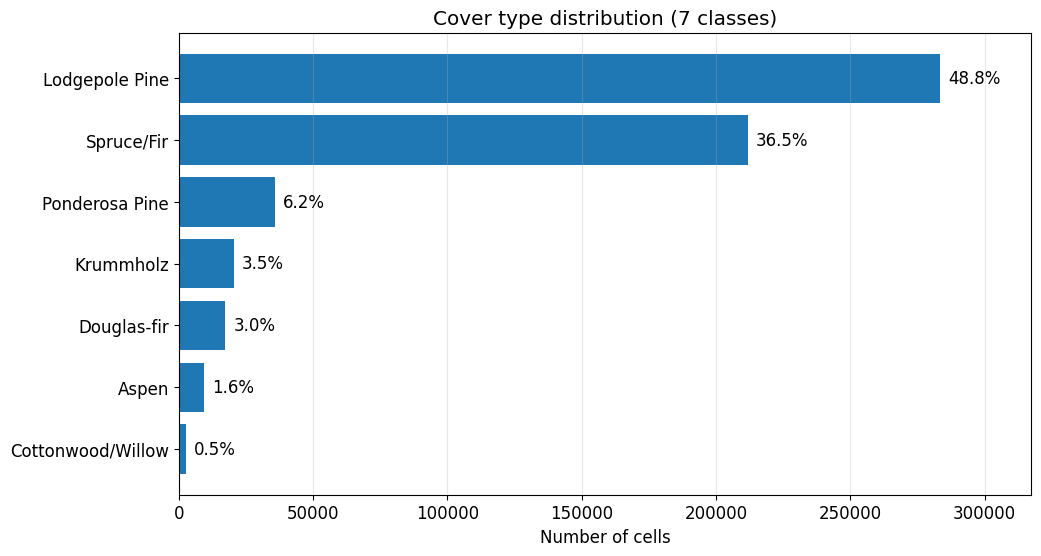

In [8]:
# plotting to visualize it
plot_data = target_summary.sort_values('Count')

plt.barh(plot_data['Cover type'], plot_data['Count'])

# Write the share next to each bar
for i, (count, share) in enumerate(zip(plot_data['Count'], plot_data['Share (%)'])):
    plt.text(count + 3000, i, f"{share:.1f}%", va='center')

plt.xlim(0, plot_data['Count'].max() * 1.12)
plt.xlabel("Number of cells")
plt.title("Cover type distribution (7 classes)")
plt.grid(axis='x', alpha=0.3)
plt.show()

- The classes are very imbalanced. Lodgepole Pine (48.8%) and Spruce/Fir (36.5%) together make up 85% of the cells.
- Cottonwood/Willow is only 0.5% (2,747 cells), about 100 times rarer than Lodgepole Pine.
- Always predicting Lodgepole Pine would already give 48.8% accuracy. A model could score a high accuracy while doing badly on the rare classes, so accuracy alone is not enough.


Therefore, I will split with `stratify=y` so every class keeps the same share in the training and test sets.
And report **macro F1** with accuracy.

### 3.3 Numeric features: distributions and scales

In [9]:
# Grab the numeric columns only
numeric_cols = list(X.columns[:10])

X[numeric_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.4,280.0,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.7,111.9,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.1,7.5,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.4,212.5,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.4,58.3,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.1,1559.3,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.1,26.8,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.3,19.8,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.5,38.3,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.3,1324.2,0.0,1024.0,1710.0,2550.0,7173.0


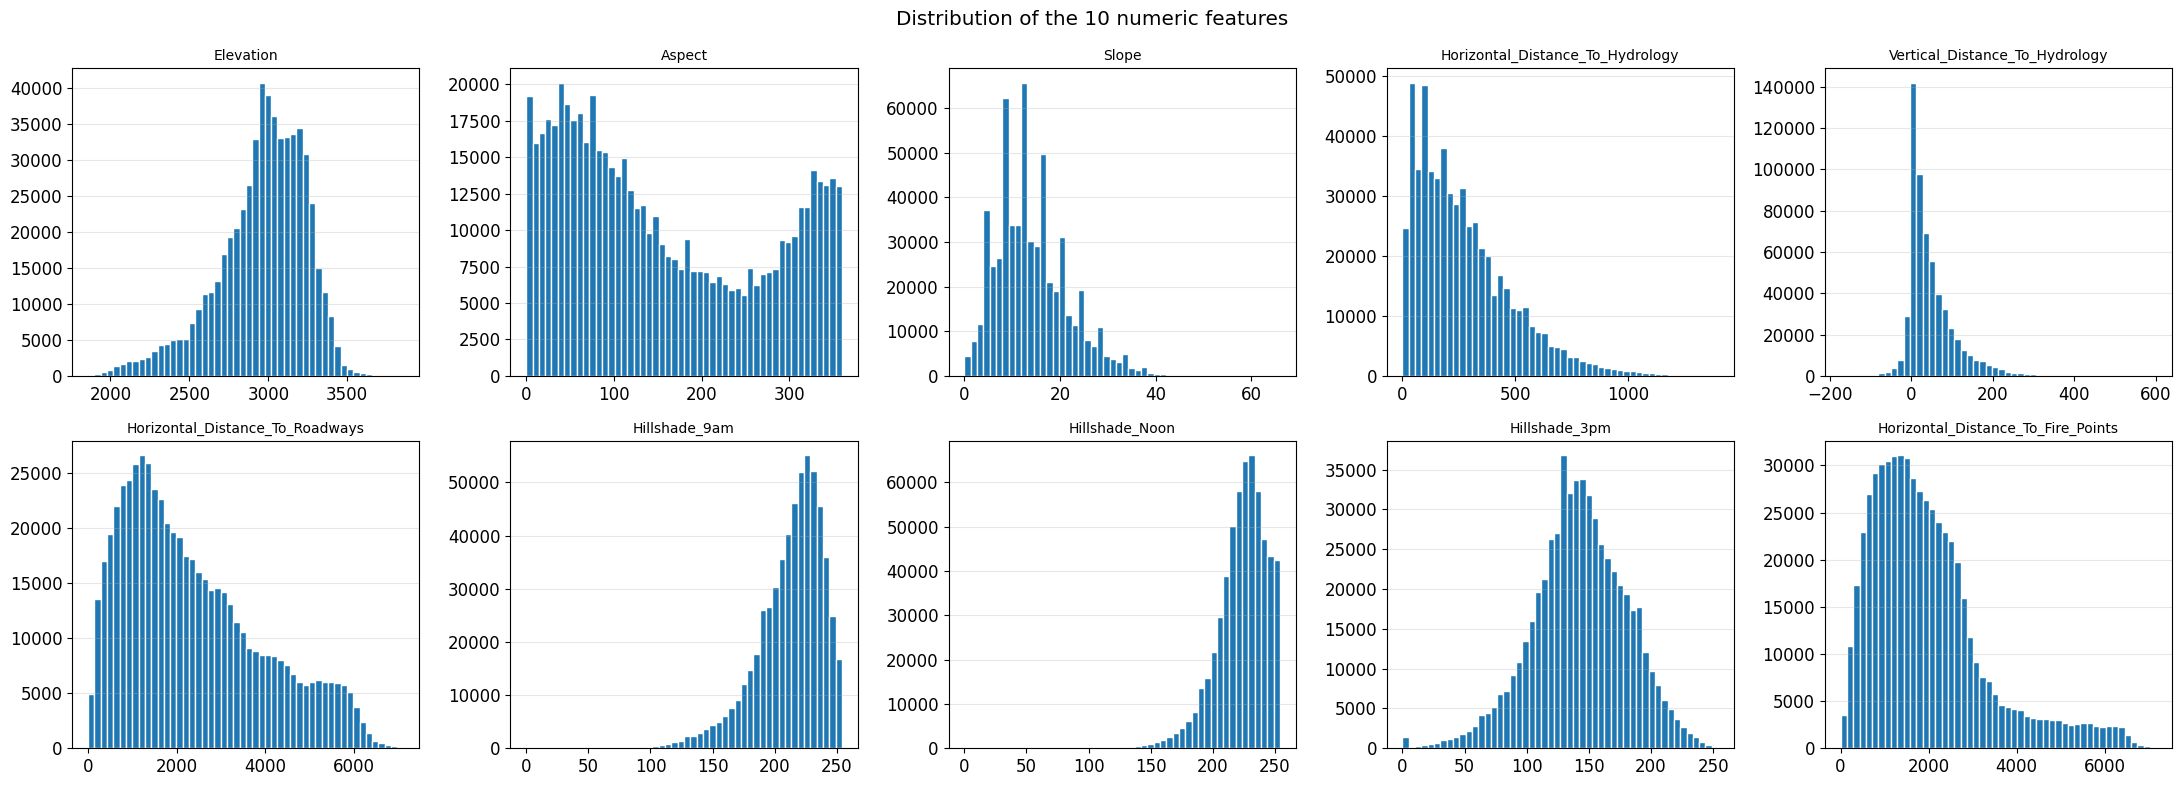

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(X[col], bins=50, edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle("Distribution of the 10 numeric features")
plt.tight_layout()
plt.show()

In [11]:
X[numeric_cols].skew().round(2)

Elevation                            -0.82
Aspect                                0.40
Slope                                 0.79
Horizontal_Distance_To_Hydrology      1.14
Vertical_Distance_To_Hydrology        1.79
Horizontal_Distance_To_Roadways       0.71
Hillshade_9am                        -1.18
Hillshade_Noon                       -1.06
Hillshade_3pm                        -0.28
Horizontal_Distance_To_Fire_Points    1.29
dtype: float64

- **The scales are very different:** `Slope` goes up to 66°, hillshade from 0 to 254, and the distances up to about 7,100 m.
- **`Elevation` covers about 2 km** of altitude (1,859 m to 3,858 m).
- **The distances are right-skewed** (`Vertical_Distance_To_Hydrology` 1.79, `Horizontal_Distance_To_Fire_Points` 1.29, `Horizontal_Distance_To_Hydrology` 1.14): most cells are fairly close to water and roads.
- **`Hillshade_9am` and `Hillshade_Noon` are left-skewed** (−1.18 and −1.06): most cells get a lot of sun in the morning and at midday.
- **`Aspect` is circular:** 0° and 360° both mean north, even though the numbers are far apart.

### 3.4 Binary features: wilderness area and soil type

In [12]:
# Grab the wilderness area columns
wilderness_cols = [f'Wilderness_Area{i}' for i in range(1, 5)]
# Grab the soil type columns
soil_cols = [f'Soil_Type{i}' for i in range(1, 41)]

In [13]:
print("Wilderness areas per row:", sorted(X[wilderness_cols].sum(axis=1).unique()))
print("Soil types per row:      ", sorted(X[soil_cols].sum(axis=1).unique()))

Wilderness areas per row: [1]
Soil types per row:       [1]


Just making sure each row has only one value

In [14]:
wilderness_share = (X[wilderness_cols].mean() * 100).round(1).rename(WILDERNESS_NAMES)
wilderness_share.rename('Share of cells (%)')

Rawah              44.9
Neota               5.1
Comanche Peak      43.6
Cache la Poudre     6.4
Name: Share of cells (%), dtype: float64

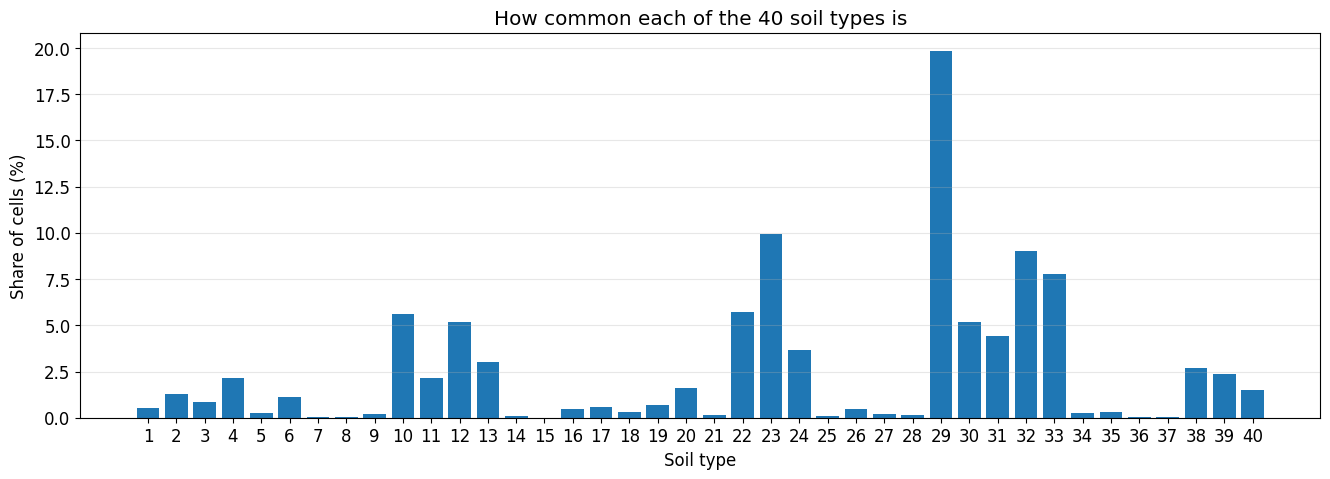

Rare soil types (< 0.1%): 6
Soil_Type15      3
Soil_Type7     105
Soil_Type36    119
Soil_Type8     179
Soil_Type37    298
Soil_Type25    474
dtype: int64


In [15]:
soil_counts = X[soil_cols].sum()
soil_share = soil_counts / len(X) * 100

plt.figure(figsize=(16, 5))
plt.bar(range(1, 41), soil_share)
plt.xticks(range(1, 41))
plt.xlabel("Soil type")
plt.ylabel("Share of cells (%)")
plt.title("How common each of the 40 soil types is")
plt.grid(axis='y', alpha=0.3)
plt.show()

rare_soils = soil_counts[soil_share < 0.1].sort_values()
print(f"Rare soil types (< 0.1%): {len(rare_soils)}")
print(rare_soils)

- Every cell has **exactly one** wilderness area and **exactly one** soil type. So these 44 columns are just two categorical variables that are already one-hot encoded.
- **Rawah (44.9%) and Comanche Peak (43.6%)** hold almost all the cells. Neota (5.1%) and Cache la Poudre (6.4%) are small.
- **The soil types are very uneven.** Soil type 29 covers 19.8% of cells, while **6 soil types appear in fewer than 0.1%**.

### 3.5 Which features separate the cover types?

In [16]:
# Average of each numeric feature for each cover type
mean_by_type = df.groupby('Cover_Type')[numeric_cols].mean().T
mean_by_type.columns = [COVER_NAMES[k] for k in mean_by_type.columns]
mean_by_type.round(0)

,Spruce/Fir,Lodgepole Pine,Ponderosa Pine,Cottonwood/Willow,Aspen,Douglas-fir,Krummholz
Elevation,3129.0,2921.0,2395.0,2224.0,2787.0,2419.0,3362.0
Aspect,156.0,152.0,176.0,137.0,139.0,181.0,153.0
Slope,13.0,14.0,21.0,19.0,17.0,19.0,14.0
Horizontal_Distance_To_Hydrology,271.0,280.0,210.0,107.0,212.0,160.0,357.0
Vertical_Distance_To_Hydrology,42.0,46.0,62.0,41.0,51.0,45.0,69.0
Horizontal_Distance_To_Roadways,2615.0,2430.0,944.0,914.0,1350.0,1037.0,2738.0
Hillshade_9am,212.0,214.0,202.0,228.0,223.0,193.0,217.0
Hillshade_Noon,223.0,225.0,216.0,217.0,219.0,210.0,222.0
Hillshade_3pm,144.0,143.0,140.0,111.0,122.0,148.0,135.0
Horizontal_Distance_To_Fire_Points,2009.0,2168.0,911.0,859.0,1578.0,1055.0,2070.0


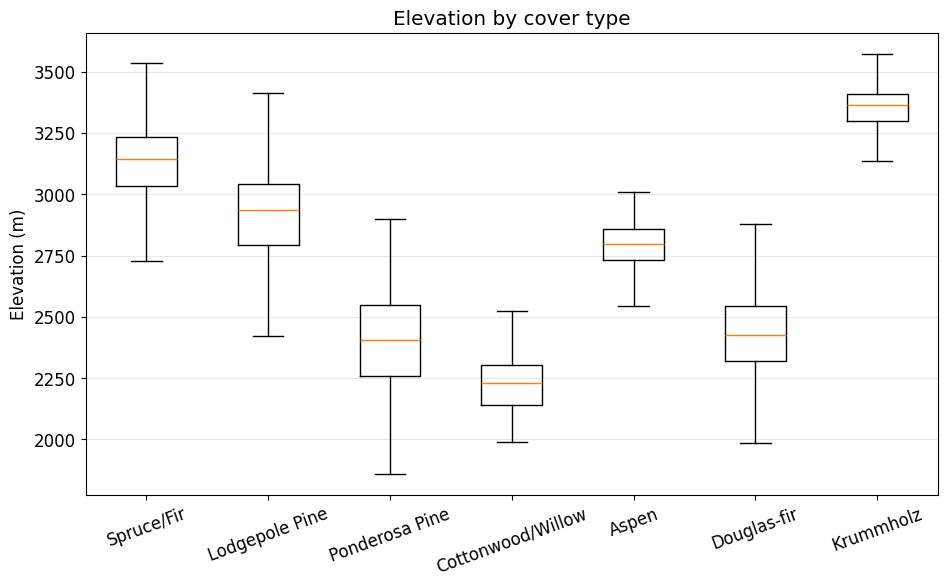

In [17]:
# Boxplot of Elevation by cover type
elevation_by_type = [df.loc[df['Cover_Type'] == k, 'Elevation'] for k in COVER_NAMES]

plt.boxplot(elevation_by_type, showfliers=False)
plt.xticks(range(1, 8), COVER_NAMES.values(), rotation=20) # type: ignore
plt.ylabel("Elevation (m)")
plt.title("Elevation by cover type")
plt.grid(axis='y', alpha=0.3)
plt.show()

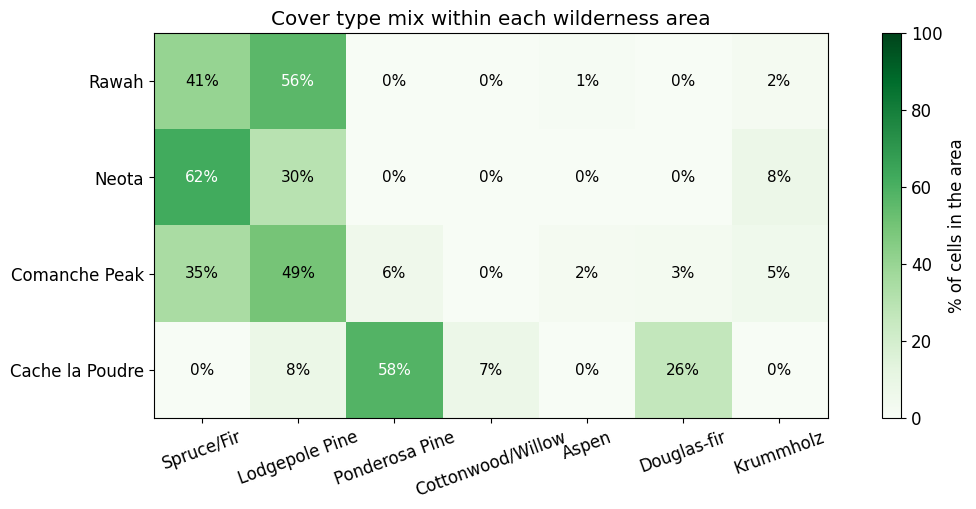

In [ ]:
# Which wilderness area each cell is in
wilderness = X[wilderness_cols].idxmax(axis=1).map(WILDERNESS_NAMES)

# Share of each cover type inside each wilderness area (each row sums to 100%)
area_vs_type = pd.crosstab(wilderness, y.map(COVER_NAMES), normalize='index') * 100
area_vs_type = area_vs_type.loc[list(WILDERNESS_NAMES.values()), list(COVER_NAMES.values())]

plt.figure(figsize=(14, 5))
plt.imshow(area_vs_type, cmap='Greens', vmin=0, vmax=100)
plt.colorbar(label="% of cells in the area")
plt.xticks(range(7), area_vs_type.columns, rotation=20) # type: ignore
plt.yticks(range(4), area_vs_type.index) # type: ignore

# Write the share inside each square
for i in range(area_vs_type.shape[0]):
    for j in range(area_vs_type.shape[1]):
        value = area_vs_type.iloc[i, j]
        plt.text(j, i, f"{value:.0f}%", ha='center', va='center', fontsize=11,
                 color='white' if value > 50 else 'black') # type: ignore

plt.title("Cover type mix within each wilderness area")
plt.show()

- **`Elevation` separates the classes best.** The median goes from about 2,230 m for Cottonwood/Willow to about 3,360 m for Krummholz.
- Two pairs overlap heavily by the wilderness area, so the model will probably mix them up:
  - **Spruce/Fir vs Lodgepole Pine**
  - **Ponderosa Pine vs Douglas-fir**
- **Distance to roads and fire points:** Ponderosa Pine, Cottonwood/Willow and Douglas-fir are on average about 900–1,050 m from the nearest road, compared with 2,400–2,750 m for Spruce/Fir, Lodgepole Pine and Krummholz. Probably because these low-elevation trees are easier to reach.
- **Wilderness area matters too.** Cache la Poudre is the only area with Cottonwood/Willow (all 2,747 cells). Ponderosa Pine makes up 58% of its cells, and it has no Spruce/Fir. The other three areas are mostly Spruce/Fir and Lodgepole Pine.

### 3.6 Correlation between numeric features

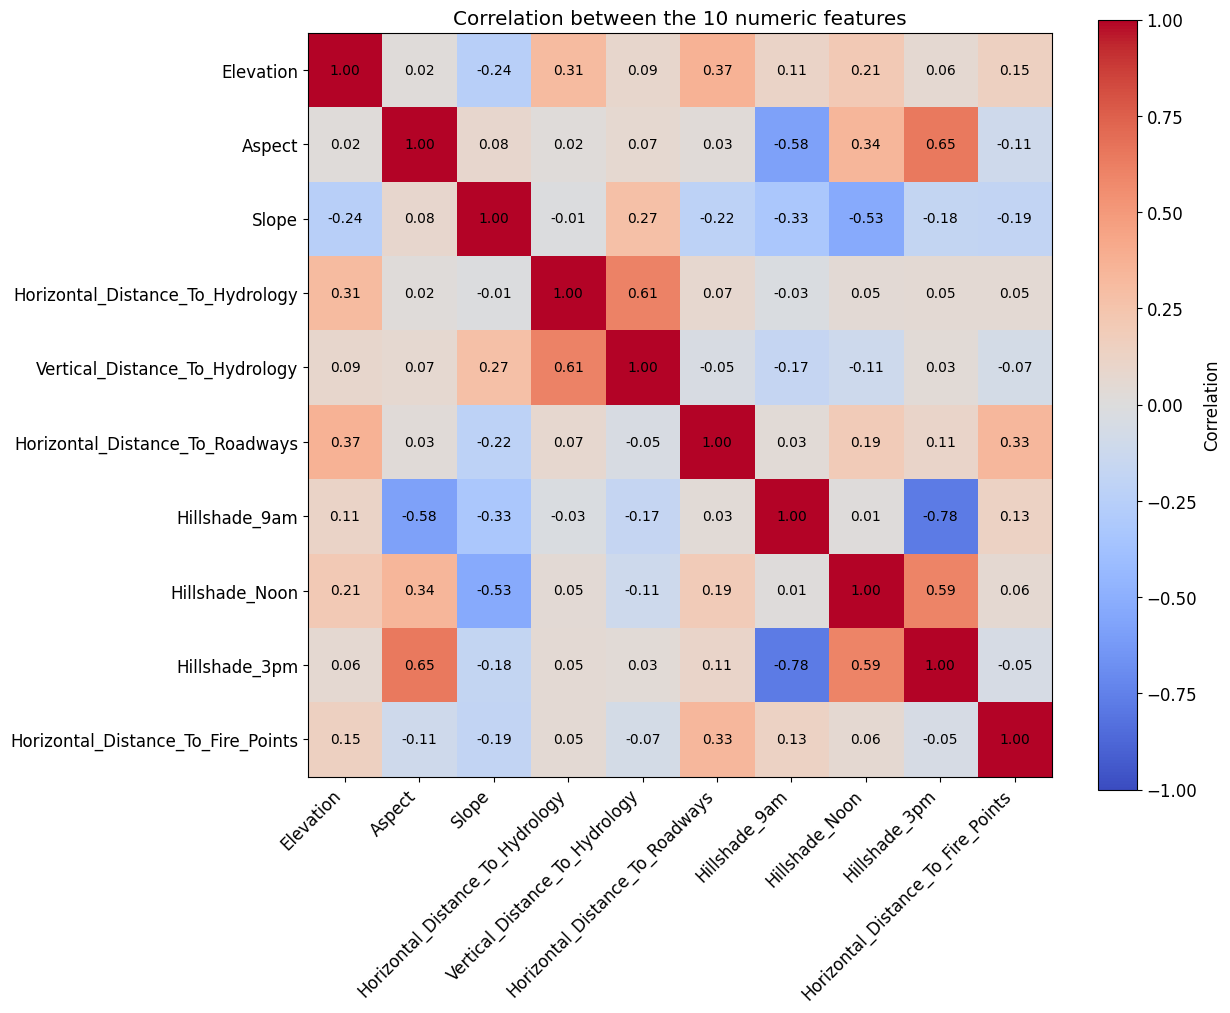

In [19]:
feature_corr = X[numeric_cols].corr()

plt.figure(figsize=(12, 10))
plt.imshow(feature_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha='right')
plt.yticks(range(len(numeric_cols)), numeric_cols)

# Write the correlation value inside each square
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)

plt.title("Correlation between the 10 numeric features")
plt.show()

- **The strongest link is `Hillshade_9am` vs `Hillshade_3pm` (−0.78).** A slope that faces east is bright in the morning and shaded in the afternoon, and a west-facing slope is the opposite.
- **`Aspect` is linked to `Hillshade_3pm` (0.65) and `Hillshade_9am` (−0.58)** for the same reason: the direction a slope faces decides when it gets sun.
- **Horizontal and vertical distance to water move together (0.61):** cells far from water also tend to sit higher above it.
- **No pair is above 0.8**, and `Elevation`'s strongest correlation is only 0.37 (distance to roads).

None of the features are redundant, so I'm keeping all of them!

### 3.7 EDA takeaways
1. **Clean data:** no missing values, no duplicates, and the categorical features are already one-hot encoded. Very little cleaning is needed.
2. **Imbalanced target:** use `stratify=y` when splitting, and use **macro F1** as the main metric, with accuracy alongside it.
3. **Very large dataset:** 5-fold `GridSearchCV` on all 581k rows would take hours. A **stratified random sample** will be used for modeling. It needs to be big enough that the rarest class (Cottonwood/Willow, 0.5%) still has enough cells in the test set.
4. **Different feature scales:** scaling is only needed for distance-based models.

## 4. Baseline Model: XGBoost

**Why XGBoost?**
- **Non-linear patterns:** cover type changes in elevation bands and depends on feature combinations (elevation + area + soil). Trees handle both.
- **No scaling needed:** trees split on thresholds, so different scales, skew and one-hot columns don't matter.
- **Learns from its mistakes:** each new tree corrects the errors of the previous ones, which helps with the overlapping classes.
- **Lots to tune:** depth, learning rate, number of trees, subsampling and regularization all control under/overfitting.

The baseline keeps XGBoost's **default hyperparameters**, so the tuned model can be compared against it fairly.

In [20]:
# Stratified sample of 50,000 cells: the full 581k rows is too slow for 5-fold CV later
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=50_000, stratify=y, random_state=42)

# XGBoost needs classes numbered from 0, so shift 1-7 down to 0-6
y_sample = y_sample - 1

# 80/20 split, statified
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.2, stratify=y_sample, random_state=42)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Cottonwood/Willow cells in the test set: {(y_test == 3).sum()}")

Train: (40000, 54)   Test: (10000, 54)
Cottonwood/Willow cells in the test set: 47


In [21]:
# Baseline: all hyperparameters left at their defaults
# (n_estimators=100, learning_rate=0.3, max_depth=6, subsample=1, colsample_bytree=1, reg_lambda=1)
baseline_model = XGBClassifier(random_state=42, n_jobs=-1)
baseline_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [22]:
y_train_pred = baseline_model.predict(X_train)
y_test_pred = baseline_model.predict(X_test)

# Train vs test scores
baseline_scores = pd.DataFrame({
    'Accuracy': [accuracy_score(y_train, y_train_pred), accuracy_score(y_test, y_test_pred)],
    'Macro F1': [f1_score(y_train, y_train_pred, average='macro'), f1_score(y_test, y_test_pred, average='macro')],
}, index=['Train', 'Test']).round(3)
display(baseline_scores)

# Precision, recall and F1
print(classification_report(y_test, y_test_pred, target_names=list(COVER_NAMES.values()), digits=3))

,Accuracy,Macro F1
Train,0.917,0.949
Test,0.849,0.803


                   precision    recall  f1-score   support

       Spruce/Fir      0.843     0.826     0.834      3646
   Lodgepole Pine      0.853     0.887     0.869      4876
   Ponderosa Pine      0.860     0.870     0.865       616
Cottonwood/Willow      0.844     0.809     0.826        47
            Aspen      0.886     0.479     0.622       163
      Douglas-fir      0.777     0.699     0.736       299
        Krummholz      0.898     0.844     0.870       353

         accuracy                          0.849     10000
        macro avg      0.852     0.773     0.803     10000
     weighted avg      0.849     0.849     0.848     10000



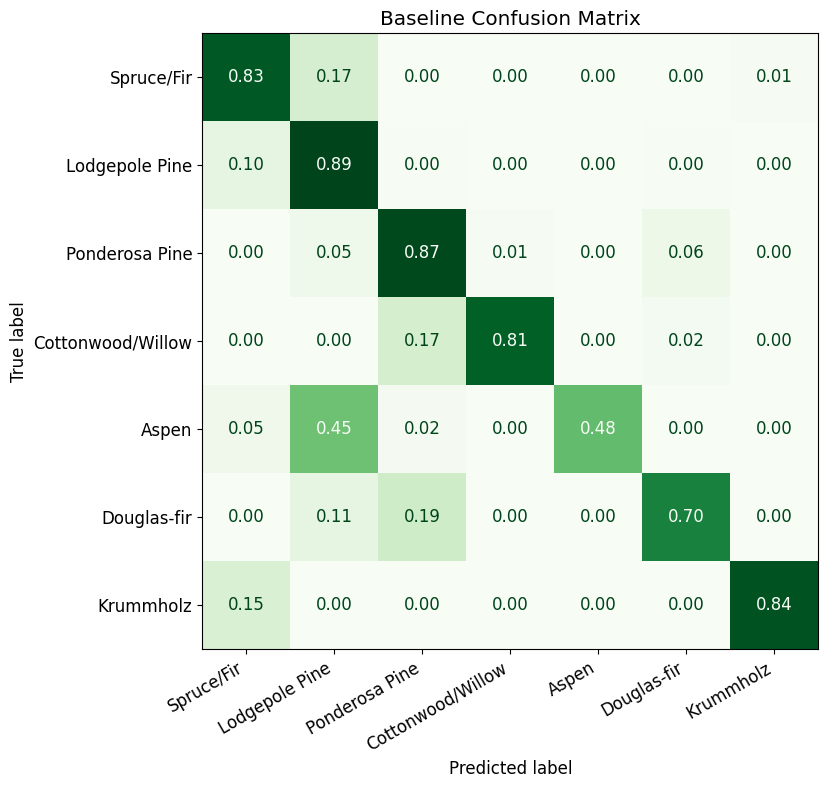

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=list(COVER_NAMES.values()),
    normalize='true', values_format='.2f', cmap='Greens', colorbar=False, ax=ax)
plt.xticks(rotation=30, ha='right')
plt.title("Baseline Confusion Matrix")
plt.show()

### Baseline takeaways
- **Test performance:** accuracy **0.849** and macro F1 **0.803**, pretty good, its not always guessing Lodgepole Pine.
- **Overfitting:** train vs test drops from 0.917 to 0.849 in accuracy and from 0.949 to 0.803 in macro F1. The gap is biggest for the rare classes, because the model memorizes their few training cells.
- **But also limited:** only 0.917 train accuracy means the default trees (depth 6, 100 trees) can't fully fit even the training data, so there is room for a stronger model.
- **Weakest class: Aspen**, with recall of only 0.48. 45% of Aspen cells are predicted as Lodgepole Pine.

## 5. Hyperparameter Optimization

**I selected `RandomizedSearchCV`: 40 random combinations × 5 folds = 200 fits.

**Scoring:** macro F1, so the rare cover types count as much as the big ones.

| Hyperparameter | Range | Why |
|---|---|---|
| `n_estimators` | 100–800 | Number of trees |
| `learning_rate` | 0.01–0.3 (log) | How much each tree corrects; lower needs more trees |
| `max_depth` | 3–14 | Tree complexity; the baseline (6) couldn't fit the training data |
| `min_child_weight` | 1–10 | Minimum data in a leaf; higher stops memorizing rare classes |
| `subsample` | 0.5–1.0 | Share of rows each tree sees |
| `colsample_bytree` | 0.5–1.0 | Share of features each tree sees |
| `reg_lambda` | 0.1–10 (log) | L2 penalty on leaf values |

In [ ]:
# Ranges to sample from
param_distributions = {
    'n_estimators': randint(100, 801),
    'learning_rate': loguniform(0.01, 0.3),
    'max_depth': randint(3, 15),
    'min_child_weight': randint(1, 11),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    'reg_lambda': loguniform(0.1, 10),
}

search = RandomizedSearchCV(
    XGBClassifier(random_state=42, n_jobs=1), # 1 thread per model
    param_distributions,
    n_iter=40,
    scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    return_train_score=True, # needed to check overfitting
    n_jobs=-1,
    random_state=42,
    verbose=1,
)
search.fit(X_train, y_train) # training data only

print(f"Best CV macro F1: {search.best_score_:.3f}")
print({p: round(v, 3) if isinstance(v, float) else v for p, v in search.best_params_.items()})

Fitting 5 folds for each of 40 candidates, totalling 200 fits


Best CV macro F1: 0.812
{'colsample_bytree': 0.944, 'learning_rate': 0.142, 'max_depth': 10, 'min_child_weight': 4, 'n_estimators': 686, 'reg_lambda': 7.435, 'subsample': 0.893}
CPU times: user 14.1 s, sys: 2.81 s, total: 16.9 s
Wall time: 2min 49s


In [ ]:
tuned_model = search.best_estimator_

y_train_pred_tuned = tuned_model.predict(X_train) # type: ignore
y_test_pred_tuned = tuned_model.predict(X_test) # type: ignore

tuned_scores = pd.DataFrame({
    'Accuracy': [accuracy_score(y_train, y_train_pred_tuned), accuracy_score(y_test, y_test_pred_tuned)],
    'Macro F1': [f1_score(y_train, y_train_pred_tuned, average='macro'), f1_score(y_test, y_test_pred_tuned, average='macro')],
}, index=['Train', 'Test']).round(3)
display(tuned_scores)

print(classification_report(y_test, y_test_pred_tuned, target_names=list(COVER_NAMES.values()), digits=3))

,Accuracy,Macro F1
Train,1.000,1.000
Test,0.899,0.845


                   precision    recall  f1-score   support

       Spruce/Fir      0.903     0.891     0.897      3646
   Lodgepole Pine      0.901     0.929     0.915      4876
   Ponderosa Pine      0.876     0.894     0.885       616
Cottonwood/Willow      0.860     0.787     0.822        47
            Aspen      0.925     0.601     0.729       163
      Douglas-fir      0.810     0.729     0.768       299
        Krummholz      0.925     0.875     0.900       353

         accuracy                          0.899     10000
        macro avg      0.886     0.815     0.845     10000
     weighted avg      0.899     0.899     0.898     10000



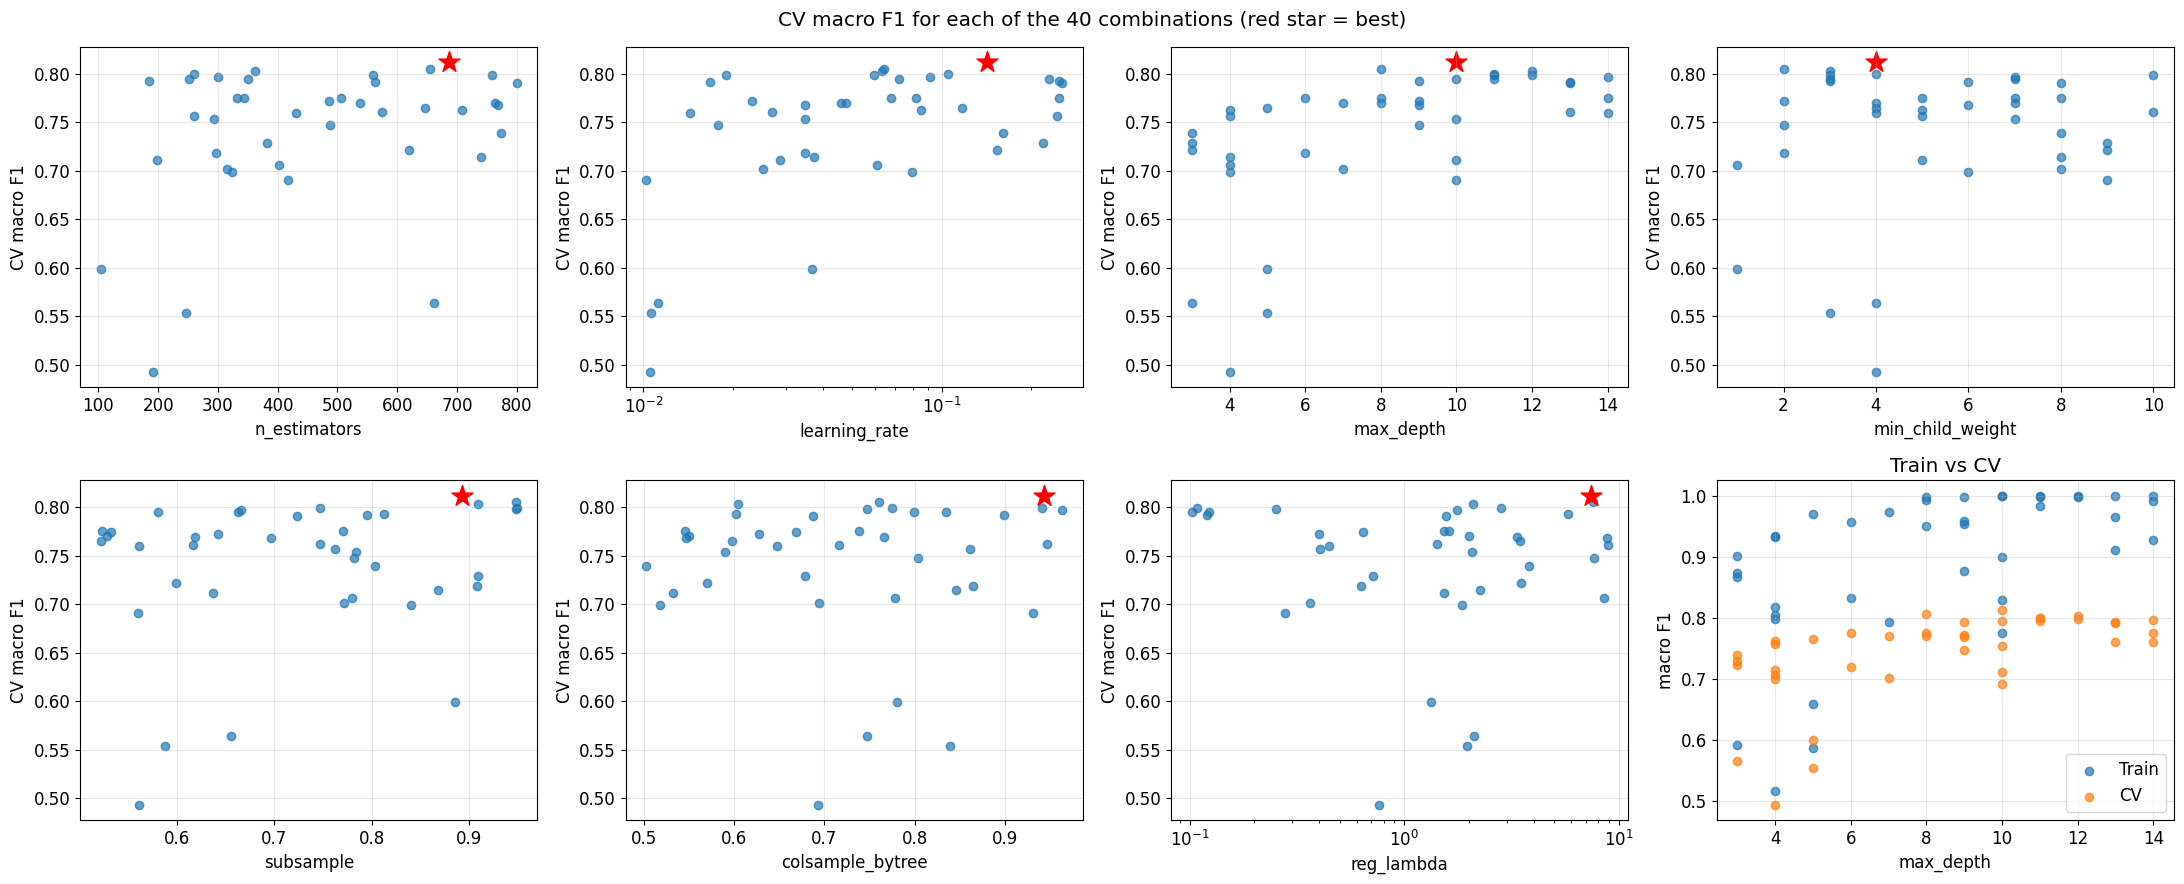

In [ ]:
results = pd.DataFrame(search.cv_results_)
best = results.loc[search.best_index_]
log_scale = ['learning_rate', 'reg_lambda']

fig, axes = plt.subplots(2, 4, figsize=(22, 9))

# One panel per hyperparameter: CV score of each of the 40 combinations
for ax, p in zip(axes.flatten(), param_distributions):
    ax.scatter(results['param_' + p].astype(float), results['mean_test_score'], alpha=0.7)
    ax.scatter(float(best['param_' + p]), best['mean_test_score'], color='red', marker='*', s=250, label='Best') # type: ignore
    if p in log_scale:
        ax.set_xscale('log')
    ax.set_xlabel(p)
    ax.set_ylabel("CV macro F1")
    ax.grid(alpha=0.3)

# Last panel: train vs CV score by depth (the gap = overfitting)
ax = axes.flatten()[-1]
depth = results['param_max_depth'].astype(int)
ax.scatter(depth, results['mean_train_score'], alpha=0.7, label='Train')
ax.scatter(depth, results['mean_test_score'], alpha=0.7, label='CV')
ax.set_xlabel("max_depth")
ax.set_ylabel("macro F1")
ax.set_title("Train vs CV")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle("CV macro F1 for each of the 40 combinations (red star = best)")
plt.tight_layout()
plt.show()

In [27]:
# How strongly each hyperparameter is linked to the CV score (Spearman rank correlation: 0 = no link, 1 = perfect)
effect = {p: results['param_' + p].astype(float).corr(results['mean_test_score'], method='spearman') for p in param_distributions}
display(pd.Series(effect, name='Spearman ρ with CV macro F1').sort_values(key=abs, ascending=False).round(2))

# Average CV score for shallow, medium and deep trees
depth_group = pd.cut(results['param_max_depth'].astype(int), [2, 5, 9, 14], labels=['3–5', '6–9', '10–14'])
display(results.groupby(depth_group, observed=True)['mean_test_score'].agg(['mean', 'count']).round(3))

# The 5 worst combinations
results.nsmallest(5, 'mean_test_score')[['param_max_depth', 'param_learning_rate', 'param_n_estimators',
                                         'mean_train_score', 'mean_test_score']].round(3)

max_depth           0.62
learning_rate       0.43
n_estimators        0.23
subsample           0.21
colsample_bytree    0.13
min_child_weight   -0.05
reg_lambda         -0.03
Name: Spearman ρ with CV macro F1, dtype: float64

,mean,count
param_max_depth,,
3–5,0.677,13
6–9,0.763,11
10–14,0.777,16


,param_max_depth,param_learning_rate,param_n_estimators,mean_train_score,mean_test_score
6,4,0.011,191,0.516,0.493
28,5,0.011,247,0.586,0.554
7,3,0.011,661,0.590,0.564
15,5,0.037,104,0.658,0.599
21,10,0.010,417,0.775,0.691


### Search takeaways
- **Best combination:** `max_depth=10`, `n_estimators=686`, `learning_rate=0.142`, `min_child_weight=4`, `subsample=0.89`, `colsample_bytree=0.94`, `reg_lambda=7.4`, with **CV macro F1 0.812**. On the test set it reaches accuracy **0.899** and macro F1 **0.845**.
- **`max_depth` mattered most:** depth 3–5 averaged 0.68 CV macro F1 and depth 10–14 averaged 0.78.
- **`learning_rate` came second:** below about 0.03 the model learns too slowly to finish within its trees. The 3 worst combinations all used 0.011.

## 6. Did Optimization Help?

,Baseline,Tuned,Change
CV macro F1,0.775,0.812,0.037
Train accuracy,0.917,1.000,0.083
Test accuracy,0.849,0.899,0.049
Train macro F1,0.949,1.000,0.051
Test macro F1,0.803,0.845,0.042


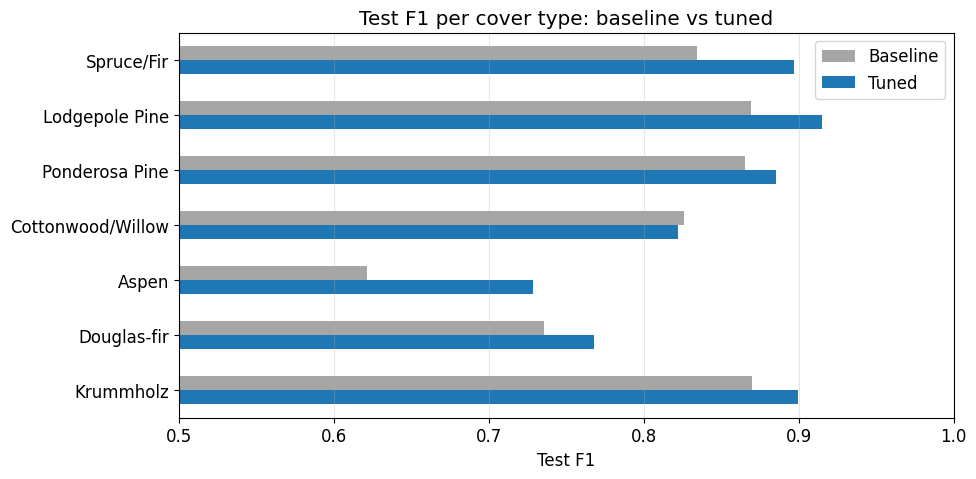

In [ ]:
# Baseline scored on the same 5 CV folds, so its CV score can be compared with the search
baseline_cv = cross_val_score(
    XGBClassifier(random_state=42, n_jobs=1), X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro', n_jobs=-1
).mean()

def all_scores(train_pred, test_pred):
    return [accuracy_score(y_train, train_pred), accuracy_score(y_test, test_pred),
            f1_score(y_train, train_pred, average='macro'), f1_score(y_test, test_pred, average='macro')]

comparison = pd.DataFrame({
    'Baseline': [baseline_cv, *all_scores(y_train_pred, y_test_pred)],
    'Tuned': [search.best_score_, *all_scores(y_train_pred_tuned, y_test_pred_tuned)],
}, index=['CV macro F1', 'Train accuracy', 'Test accuracy', 'Train macro F1', 'Test macro F1'])
comparison['Change'] = comparison['Tuned'] - comparison['Baseline']
display(comparison.round(3))

# F1 of each cover type on the same test set
per_class = pd.DataFrame({
    'Baseline': f1_score(y_test, y_test_pred, average=None),
    'Tuned': f1_score(y_test, y_test_pred_tuned, average=None),
}, index=list(COVER_NAMES.values()))

per_class.plot.barh(color=['#A6A6A6', '#1F77B4'], figsize=(10, 5))
plt.gca().invert_yaxis()
plt.xlim(0.5, 1)
plt.xlabel("Test F1")
plt.title("Test F1 per cover type: baseline vs tuned")
plt.grid(axis='x', alpha=0.3)
plt.show()

### Conclusions
Hyperparameter optimization helped, on the same test set, accuracy rose from 0.849 to **0.899 (+4.9 points)** and macro F1 from 0.803 to **0.845 (+4.2)**. The tuned model is better on 6 of 7 classes. Aspen gained the most (F1 0.62 → 0.73), and Cottonwood/Willow stayed about the same.
The Hyperparameters that mattered the most are `max_depth`, then `learning_rate`. The baseline's depth of 6 was too shallow, so the search moved to depth 10 with more trees.
The baseline **overfits** (train accuracy 0.917). The tuned model memorizes the training set (train 1.000), so it **overfits** too, but its test score still went up: the extra capacity helped more than the overfitting hurt.